# PharmaML — The Complete Deep Learning Workflow

One notebook, every stage of a QSAR deep-learning project, in the order
you would actually run it — from a shipped descriptor table to trained
PyTorch networks with early stopping, honest validation curves and a
proper regression/classification evaluation:

| § | Stage | Toolkit |
|---|---|---|
| 1 | **Data entry** — the shipped QSAR regression table | `pharmaml.data` |
| 2 | Train/test split — stratified, seed-reproducible | `pharmaml.ml` |
| 3 | First network — `DeepMLPRegressor`, the sklearn contract | `pharmaml.ml.neural` |
| 4 | The training story — loss curves + the early-stopping verdict | `pharmaml.viz` |
| 5 | Evaluate — parity scatter, residuals, R²/RMSE/MAE | `pharmaml.ml` + `viz` |
| 6 | Architecture comparison — plain vs residual stack | `pharmaml.ml.neural` |
| 7 | The registry path — `train_model("dnn", ...)` | `pharmaml.ml` |
| 8 | Classification — `DeepMLPClassifier` + confusion matrix | `neural` + `viz` |
| 9 | Export — the per-epoch history record as CSV | pandas |
| 10 | Recap | — |

The estimators need PyTorch (`pip install 'pharmaml[deep]'`); without
it they raise an actionable `DependencyError` at `fit` time — nothing
else in the toolkit requires torch.  Every number in this notebook is
produced by the cells below (seeded, CPU); nothing is hand-written.

The desktop GUI (`python playground.py` → *Deep Learning* tab) wraps
exactly this API — this notebook is the same workflow for readers who
prefer the terminal.


In [1]:
import sys
import tempfile
import time
from pathlib import Path

import pandas as pd

from pharmaml import __version__

pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 110)

try:
    import torch  # noqa: F401  (the deep extra)
except ImportError:
    sys.exit("PyTorch is required for this notebook:  pip install 'pharmaml[deep]'")

# Scratch directory for this run's artifacts (use any path you like).
WORK = Path(tempfile.mkdtemp(prefix="dl_workflow_"))

# The shipped demo inventory (examples/data) — this notebook loads its
# demo tables from there instead of fabricating them inline.
DATA_DIR = Path("data")

print(f"pharmaml {__version__} · torch {torch.__version__}")
print(f"artifacts -> {WORK}")


pharmaml 1.2.230 · torch 2.14.1+cpu
artifacts -> /tmp/dl_workflow_pq_hxexk


## 1 · Data entry — the shipped QSAR regression table

The regression demo table ships as `examples/data/qsar_regression.csv`
(`make_synthetic_qsar_data.py`, seed 21): 20 numeric descriptors + a
continuous pIC50 endpoint.  `load_dataset` audits the table, resolves
the target column and keeps only numeric feature columns — the same
entry point every other workflow notebook uses.  (In your project:
point the path at your own CSV.)


In [2]:
from pharmaml.data import load_dataset

reg_file = DATA_DIR / "qsar_regression.csv"     # <- replace with your own file
ds = load_dataset(reg_file, target="pIC50")

print(ds.summary())
print("task:", ds.task, "| target:", ds.target)
ds.frame.head(3)


source        : data/qsar_regression.csv
shape         : 260 rows x 21 columns (20 features (numeric))
target        : pIC50
task          : regression
missing cells : 0
dup. rows     : 0
task: regression | target: pIC50


,descr_000,descr_001,descr_002,descr_003,descr_004,descr_005,...,descr_015,descr_016,descr_017,descr_018,descr_019,pIC50
0,0.358773,1.510677,-1.786331,1.686614,-0.047317,-0.799979,...,-3.350434,0.729266,-1.395026,-0.677066,1.948369,3.0
1,-0.223645,0.833884,0.584064,0.638286,-1.694808,-1.570962,...,0.820513,1.039345,1.147329,1.497751,0.117759,3.0
2,2.183214,1.209816,-1.024391,1.285272,0.628394,0.214825,...,-2.233902,1.257396,-1.115224,-1.296305,-1.229330,3.0


## 2 · Train/test split

`make_train_test_split` is the single split helper the toolkit trusts:
seed-reproducible, classification-stratifying (a no-op for regression
targets).  The network's own validation split (§3) is carved out of the
*training* half at `fit` time, so the test half below stays a honest,
once-only estimate.


In [3]:
from pharmaml.ml.preprocessing import make_train_test_split

X_train, X_test, y_train, y_test = make_train_test_split(
    ds.X, ds.y, test_size=0.25, random_state=42,
)
print(f"train: {X_train.shape}  test: {X_test.shape}")


train: (195, 20)  test: (65, 20)


## 3 · Your first network — `DeepMLPRegressor`

The four estimators in `pharmaml.ml.neural` follow the full
scikit-learn contract — `fit` / `predict` / `score`, `get_params` /
`set_params`, clonable by `GridSearchCV` — so they drop into any
sklearn-shaped code you already have.  Training is minibatch Adam with
weight decay, per-feature standardisation fitted on the training data
only, and **early stopping**: a held-out validation fraction
(`val_split`) is scored every epoch and the best-validation weights
are the ones restored at the end.

Every knob is a constructor parameter; nothing is global state.


In [4]:
from pharmaml.ml.neural import DeepMLPRegressor

net = DeepMLPRegressor(
    hidden_layers=(16, 8),   # two hidden decks, tapering
    dropout=0.1,
    epochs=60,               # the *cap*; early stopping usually ends sooner
    batch_size=32,
    learning_rate=1e-3,
    weight_decay=1e-4,
    patience=10,             # stop after 10 epochs without val improvement
    val_split=0.15,          # held-out validation fraction for early stopping
    random_state=42,         # seeds torch + numpy -> reproducible on CPU
)

t0 = time.perf_counter()
net.fit(X_train, y_train)
fit_seconds = time.perf_counter() - t0

print(f"trained in {fit_seconds:.2f} s · epochs run: {net.n_iter_}")
print("hidden_layers:", net.get_params()["hidden_layers"])


trained in 3.50 s · epochs run: 60
hidden_layers: (16, 8)


In [5]:
# The per-epoch history record: one dict per epoch, loss on the
# training and the validation split.  This IS the evidence trail --
# the next section plots it.
history_frame = pd.DataFrame(net.history_)
print(f"{len(history_frame)} epochs recorded")

best = history_frame.loc[history_frame["val_loss"].idxmin()]
best_frame = best.to_frame("value")
best_frame


60 epochs recorded


,value
epoch,60.000000
train_loss,0.114403
val_loss,0.218340


## 4 · The training story — loss curves and the early-stopping verdict

`plot_training_history` renders both loss curves, marks the
best-validation epoch with a dashed line (the weights actually
restored) and writes the verdict in the title:

* *"early stopped N epoch(s) after the best"* — patience fired, the
  network stopped generalising further;
* *"still improving — more epochs may pay off"* — the cap (`epochs`),
  not patience, ended the run;
* *"no validation split"* — `val_split=0` was chosen, so only the
  training curve exists (and early stopping is off).


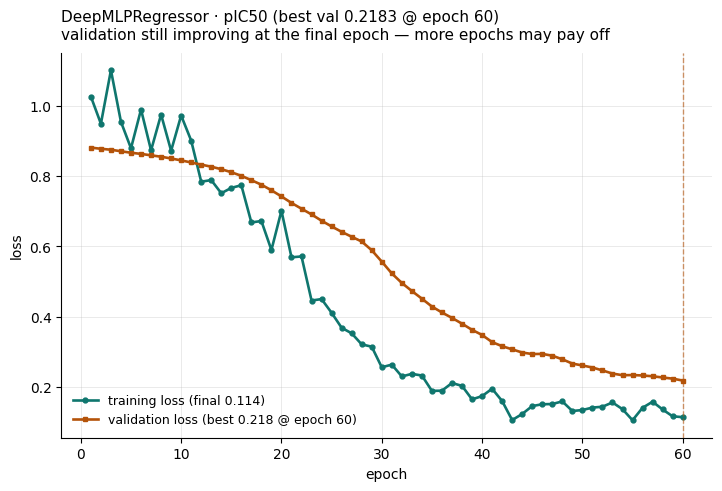

In [6]:
from pharmaml.viz import plot_training_history

fig_history = plot_training_history(
    net.history_,
    title=f"DeepMLPRegressor · {ds.target} (best val {best['val_loss']:.4f} @ epoch {int(best['epoch'])})",
)


## 5 · Evaluate — parity scatter and residuals

`evaluate_model` works on the neural estimators exactly like on any
registry model (it is the same `RegressionReport`).  Keep
`keep_predictions=True` to get the parity and residual views.


R²    0.8434
RMSE  1.1207 pIC50 units
MAE   0.9253


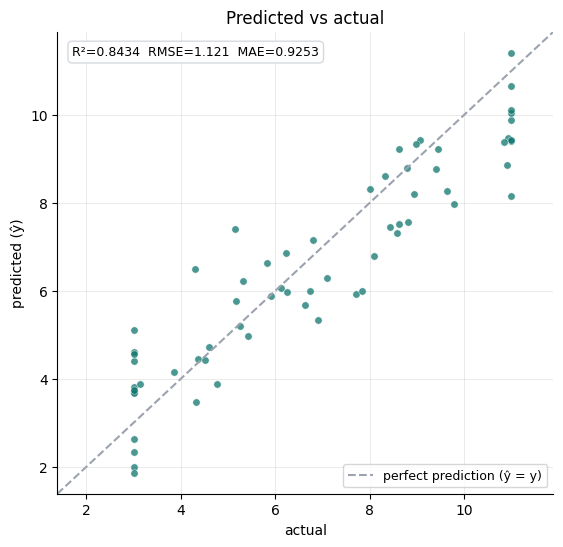

In [7]:
from pharmaml.ml import evaluate_model
from pharmaml.viz import plot_predicted_vs_actual

report = evaluate_model(net, X_test, y_test, "regression", keep_predictions=True)

print(f"R²    {report.r2:.4f}")
print(f"RMSE  {report.rmse:.4f} pIC50 units")
print(f"MAE   {report.mae:.4f}")

fig_parity = plot_predicted_vs_actual(
    y_test,
    report.predictions,
    metrics={"R²": report.r2, "RMSE": report.rmse, "MAE": report.mae},
)


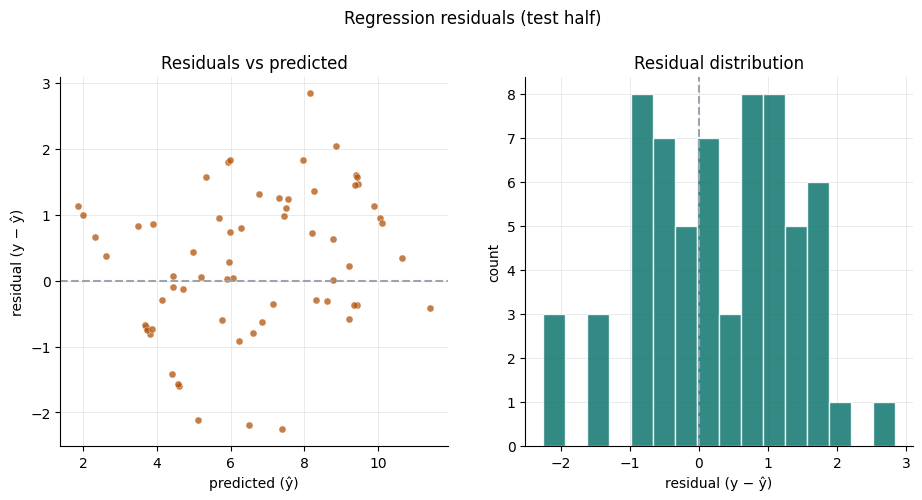

In [8]:
from pharmaml.viz import plot_residuals

fig_residuals = plot_residuals(
    y_test, report.predictions, title="Regression residuals (test half)",
)


## 6 · Architecture comparison — plain vs residual stack

`ResidualMLPRegressor` inserts learned linear skip projections between
hidden decks: the gradient can route *around* a deck, which keeps deep
stacks trainable.  On a 20-descriptor table a plain `(16, 8)` stack is
already enough — the point of this section is the *protocol*: same
split, same seed, same cap, only the architecture differs, and the
history record makes the comparison auditable epoch by epoch.


In [9]:
from pharmaml.ml.neural import ResidualMLPRegressor

res_net = ResidualMLPRegressor(
    hidden_layers=(16, 16, 16),   # same total width, residual skips between decks
    dropout=0.1,
    epochs=60,
    batch_size=32,
    learning_rate=1e-3,
    weight_decay=1e-4,
    patience=10,
    val_split=0.15,
    random_state=42,
)

t0 = time.perf_counter()
res_net.fit(X_train, y_train)
res_seconds = time.perf_counter() - t0

res_report = evaluate_model(res_net, X_test, y_test, "regression")

comparison = pd.DataFrame(
    {
        "DeepMLP (16,8)": [
            report.r2, report.rmse, report.mae, net.n_iter_, fit_seconds,
        ],
        "ResidualMLP (16,16,16)": [
            res_report.r2, res_report.rmse, res_report.mae,
            res_net.n_iter_, res_seconds,
        ],
    },
    index=["R²", "RMSE", "MAE", "epochs run", "fit seconds"],
)
print(f"residual trained in {res_seconds:.2f} s · epochs run: {res_net.n_iter_}")
comparison.round(4)


residual trained in 0.40 s · epochs run: 46


,"DeepMLP (16,8)","ResidualMLP (16,16,16)"
R²,0.8434,0.8742
RMSE,1.1207,1.0047
MAE,0.9253,0.7656
epochs run,60.0000,46.0000
fit seconds,3.4985,0.4044


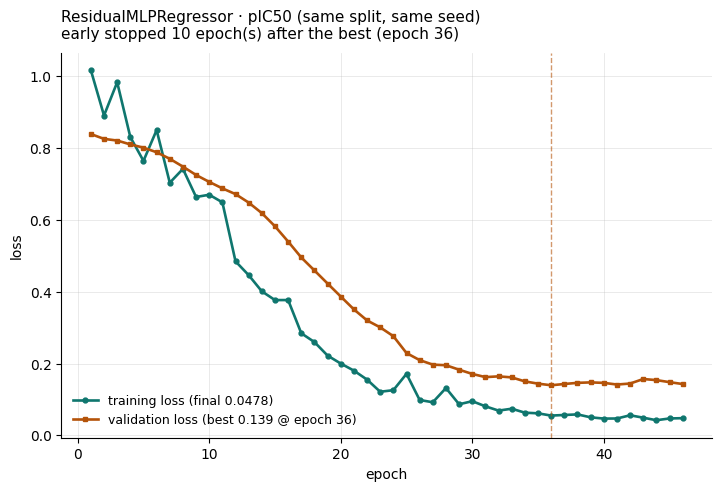

In [10]:
fig_res_history = plot_training_history(
    res_net.history_,
    title="ResidualMLPRegressor · pIC50 (same split, same seed)",
)


## 7 · The registry path — `train_model("dnn", ...)`

The same estimators sit behind the registry keys `dnn` /
`dnn_residual`, wrapped in the standard impute + scale pipeline, so a
one-line `train_model` call — the classic-model call from the ML
notebook — is all it takes.  `tune=False` fits the defaults (tuning
re-runs the fit per grid point; the cellline notebook shows the tuned
leaderboard version).

Expect the registry R² to differ slightly from the direct path (§5):
the wrapped estimator sees imputed, standardised inputs, so its
optimisation path — batches, gradients, the early-stopping epoch —
runs over different numbers.  Same estimator family, same seed, same
split; different (here: better) local minimum.


In [11]:
from pharmaml.ml import train_model

registry_result = train_model(
    "dnn", "regression", X_train, y_train,
    tune=False, random_state=42,
)
registry_report = evaluate_model(registry_result.model, X_test, y_test, "regression")

print("registry spec:", registry_result.name)
print(f"R² via registry path: {registry_report.r2:.4f}  (direct path: {report.r2:.4f})")


registry spec: dnn
R² via registry path: 0.8665  (direct path: 0.8434)


## 8 · Classification — `DeepMLPClassifier`

Same contract, discrete endpoint: the classification demo table (420
compounds, 8 descriptors, 3-level activity) enters through the same
`load_dataset` call — the SMILES/ID columns are audited out of the
feature matrix automatically.  `evaluate_model` returns the
`ClassificationReport`; the confusion matrix closes the loop.


In [12]:
cls_file = DATA_DIR / "qsar_classification.csv"   # <- replace with your own file
ds_cls = load_dataset(cls_file, target="activity")

print(ds_cls.summary())
print("classes:", ds_cls.frame["activity"].value_counts().to_dict())


Excluding 2 non-numeric column(s) from features: ['SMILES', 'compound_id']


source        : data/qsar_classification.csv
shape         : 420 rows x 11 columns (8 features (numeric))
target        : activity
task          : classification
missing cells : 0
dup. rows     : 0
classes (3): 'active': 118, 'inactive': 147, 'weak': 155
dropped cols  : SMILES, compound_id  [non-numeric]
classes: {'weak': 155, 'inactive': 147, 'active': 118}


epochs run: 60


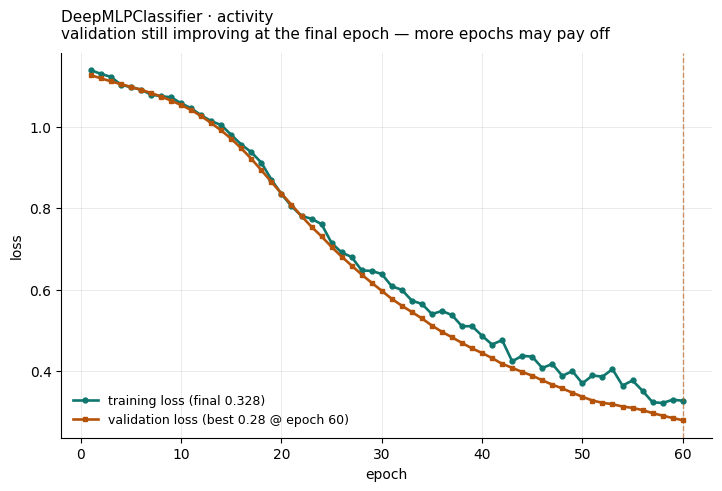

In [13]:
from pharmaml.ml.neural import DeepMLPClassifier

cX_train, cX_test, cy_train, cy_test = make_train_test_split(
    ds_cls.X, ds_cls.y, test_size=0.25, random_state=42,
)

clf = DeepMLPClassifier(
    hidden_layers=(16, 8), dropout=0.1, epochs=60, batch_size=32,
    learning_rate=1e-3, weight_decay=1e-4, patience=10, val_split=0.15,
    random_state=42,
)
clf.fit(cX_train, cy_train)
print(f"epochs run: {clf.n_iter_}")

fig_cls_history = plot_training_history(
    clf.history_, title="DeepMLPClassifier · activity",
)


accuracy 0.9143
ROC-AUC  0.9991 (one-vs-rest, macro)


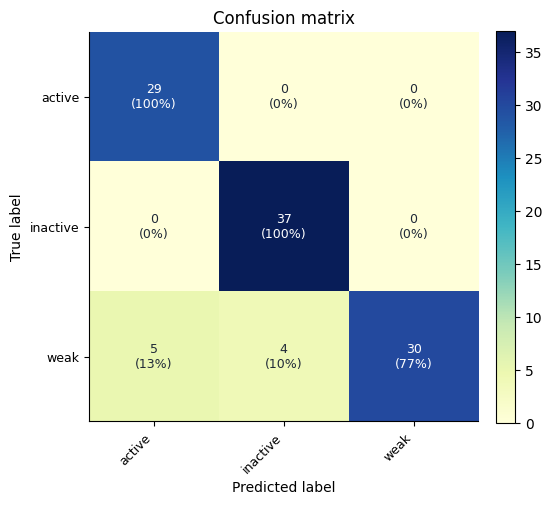

In [14]:
from pharmaml.viz import plot_confusion_matrix

cls_report = evaluate_model(clf, cX_test, cy_test, "classification")

print(f"accuracy {cls_report.accuracy:.4f}")
print(f"ROC-AUC  {cls_report.roc_auc:.4f} (one-vs-rest, macro)")

fig_confusion = plot_confusion_matrix(
    cls_report.confusion, labels=cls_report.labels,
)


## 9 · Export — the per-epoch history record as CSV

The history record is plain data (a list of dicts); one `DataFrame`
round-trip later it is a file your lab notebook, plotting tool or
reviewer can read without `pharmaml` installed.


In [15]:
history_path = WORK / "training_history.csv"
history_frame.to_csv(history_path, index=False)

round_trip = pd.read_csv(history_path)
print(f"wrote {history_path} ({len(round_trip)} rows)")
round_trip.tail(3)


wrote /tmp/dl_workflow_pq_hxexk/training_history.csv (60 rows)


,epoch,train_loss,val_loss
57,58,0.136095,0.227039
58,59,0.116636,0.223769
59,60,0.114403,0.218340


## 10 · Recap

| Stage | One-liner |
|---|---|
| Load data | `ds = load_dataset("my.csv", target="pIC50")` |
| Split | `X_tr, X_te, y_tr, y_te = make_train_test_split(ds.X, ds.y, random_state=42)` |
| Network | `DeepMLPRegressor(hidden_layers=(16, 8), patience=10).fit(X_tr, y_tr)` |
| History | `pd.DataFrame(net.history_)` · `plot_training_history(net.history_)` |
| Early stop | best-validation weights restored; `net.n_iter_` = epochs actually run |
| Evaluate | `evaluate_model(net, X_te, y_te, "regression")` → R²/RMSE/MAE |
| Residual | `ResidualMLPRegressor(hidden_layers=(16, 16, 16))` — same contract |
| Registry | `train_model("dnn", "regression", X_tr, y_tr)` — impute + scale wrapped |
| Classify | `DeepMLPClassifier(...)` + `plot_confusion_matrix(report.confusion, ...)` |
| Export | `history_frame.to_csv("training_history.csv", index=False)` |

Next steps: the *Data & ML* and *Deep Learning* tabs of
`python playground.py` expose this exact API point-and-click; the
cellline notebook puts `dnn`/`dnn_residual` on a cross-validated
leaderboard against the classical models.
